In [1]:
# --------- Explorating Data Analysis ----------

# Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Set the visual style for our charts
sns.set_theme(style="whitegrid")

print("Loading clean data...")

# Load the CSV
df_nola = pd.read_csv('../data/nola_restaurants_clean.csv')

print(f'Data loaded successfully! Total restaurants: {df_nola.shape[0]}\n')

Loading clean data...
Data loaded successfully! Total restaurants: 1480



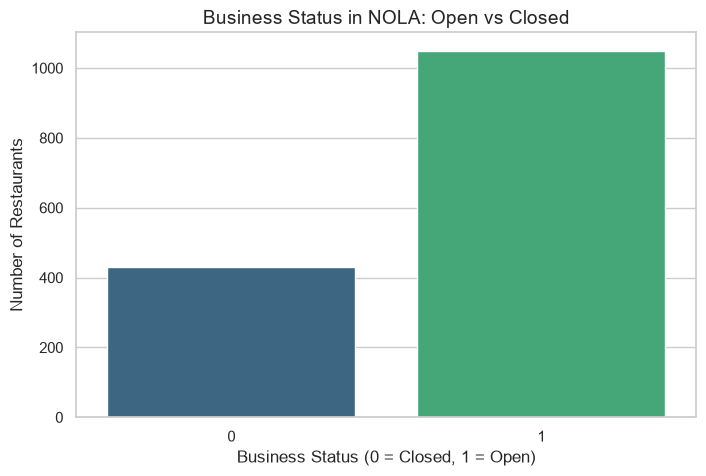

In [4]:
# Plot 1: Target Variable Distribution (is_open)
plt.figure(figsize=(8, 5))
sns.countplot(data=df_nola, x='is_open', hue='is_open', palette='viridis', legend=False)

plt.title('Business Status in NOLA: Open vs Closed', fontsize= 14)
plt.xlabel('Business Status (0 = Closed, 1 = Open)', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.show()

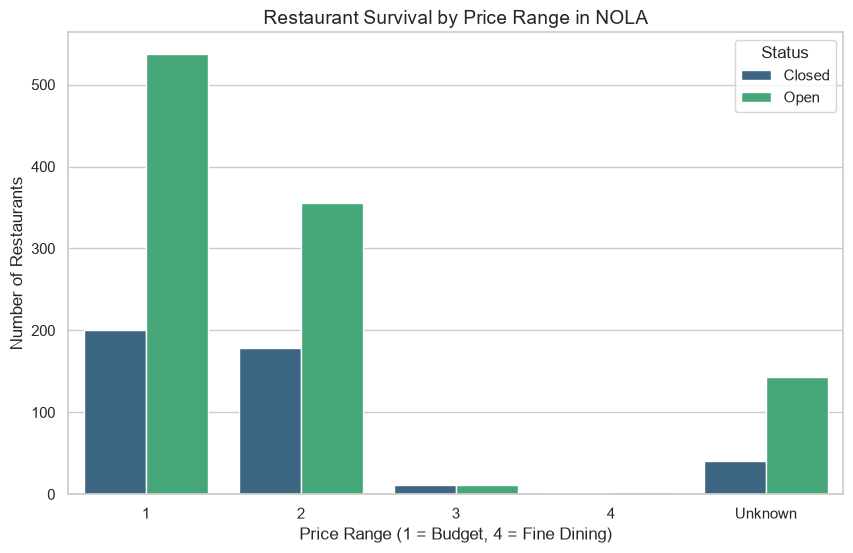

-> SURVIVAL RATE BY PRICE RANGE (%):
attr_RestaurantsPriceRange2
1          72.86
2          66.67
3          50.00
4          75.00
Unknown    78.14
Name: is_open, dtype: float64


In [8]:
# Plot 2: Price Range VS Business Status

# Ensure price range is treated as string for clean plotting
df_nola['attr_RestaurantsPriceRange2'] = df_nola['attr_RestaurantsPriceRange2'].astype(str)

# Sort categories logically
price_order = sorted(df_nola['attr_RestaurantsPriceRange2'].unique())

plt.figure(figsize=(10,6))
sns.countplot(
    data = df_nola,
    x = 'attr_RestaurantsPriceRange2',
    hue = 'is_open',
    order = price_order,
    palette='viridis'
)

plt.title('Restaurant Survival by Price Range in NOLA', fontsize=14)
plt.xlabel('Price Range (1 = Budget, 4 = Fine Dining)', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.legend(title='Status', labels=['Closed', 'Open'])
plt.show()

#Print exact survival rate (%) per price category
print("-> SURVIVAL RATE BY PRICE RANGE (%):")
survival_by_price = df_nola.groupby('attr_RestaurantsPriceRange2')['is_open'].mean() * 100
print(survival_by_price.round(2))

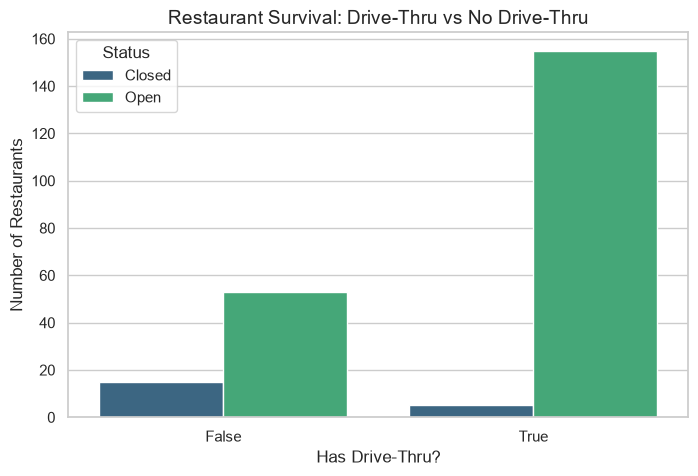

-> SURVIVAL RATE BY DRIVE-THRU (%):
attr_DriveThru
False    77.94
True     96.88
Name: is_open, dtype: float64


In [ ]:
#Plot 3: Drive-Thru vs No Drive-Thru
# 1. Filter only restaurants with 'True' or 'False' for DriveThru
df_drivethru = df_nola[df_nola['attr_DriveThru'].isin(['True', 'False'])]

# 2. Plot the bar chart
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_drivethru,
    x='attr_DriveThru',          
    hue='is_open',         
    palette='viridis'
)

plt.title('Restaurant Survival: Drive-Thru vs No Drive-Thru', fontsize=14)
plt.xlabel('Has Drive-Thru?', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.legend(title='Status', labels=['Closed', 'Open'])
plt.show()

# 3. Calculate the survival rate (%) for each group
print("-> SURVIVAL RATE BY DRIVE-THRU (%):")
survival_dt = df_drivethru.groupby('attr_DriveThru')['is_open'].mean() * 100
print(survival_dt.round(2))

Lunch: 419 restaurants | Survival Rate: 78.52%
Dinner: 236 restaurants | Survival Rate: 76.27%


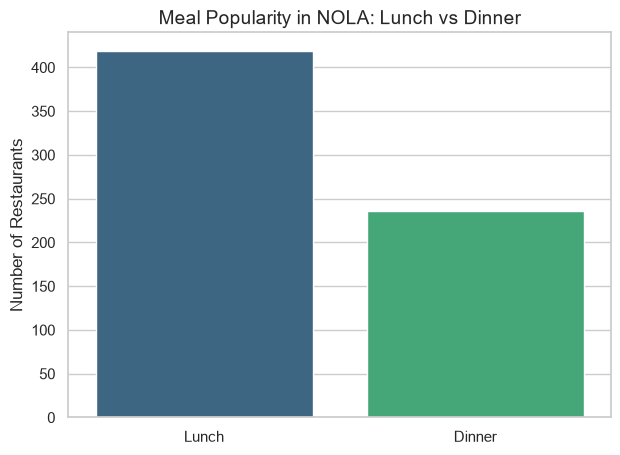

In [18]:
# Plot 4: Volume: Lunch vs Dinner

# Filter out 'Unknown' values from attr_GoodForMeal
df_meals = df_nola[df_nola['attr_GoodForMeal'] != 'Unknown'].copy()

# Extract boolean flags for Lunch and Dinner
df_meals['is_lunch'] = df_meals['attr_GoodForMeal'].str.contains("'lunch': True")
df_meals['is_dinner'] = df_meals['attr_GoodForMeal'].str.contains("'dinner': True")

# Calculate total count and survival rate (%) for each meal type
lunch_count = df_meals['is_lunch'].sum()
dinner_count = df_meals['is_dinner'].sum()

lunch_survival = df_meals[df_meals['is_lunch']]['is_open'].mean() * 100
dinner_survival = df_meals[df_meals['is_dinner']]['is_open'].mean() * 100

print(f"Lunch: {lunch_count} restaurants | Survival Rate: {lunch_survival:.2f}%")
print(f"Dinner: {dinner_count} restaurants | Survival Rate: {dinner_survival:.2f}%")

# Plot comparison
plt.figure(figsize=(7, 5))
sns.barplot(x=['Lunch', 'Dinner'], y=[lunch_count, dinner_count], hue=['Lunch', 'Dinner'], palette='viridis', legend=False)
plt.title('Meal Popularity in NOLA: Lunch vs Dinner', fontsize=14)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.show()

